In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#load the dataset
df = pd.read_csv("/content/epl_final (1).csv")
print(df.head())
print(df.shape)
print(df.columns)

    Season   MatchDate  HomeTeam       AwayTeam  FullTimeHomeGoals  \
0  2000/01  2000-08-19  Charlton       Man City                  4   
1  2000/01  2000-08-19   Chelsea       West Ham                  4   
2  2000/01  2000-08-19  Coventry  Middlesbrough                  1   
3  2000/01  2000-08-19     Derby    Southampton                  2   
4  2000/01  2000-08-19     Leeds        Everton                  2   

   FullTimeAwayGoals FullTimeResult  HalfTimeHomeGoals  HalfTimeAwayGoals  \
0                  0              H                  2                  0   
1                  2              H                  1                  0   
2                  3              A                  1                  1   
3                  2              D                  1                  2   
4                  0              H                  2                  0   

  HalfTimeResult  ...  HomeShotsOnTarget  AwayShotsOnTarget  HomeCorners  \
0              H  ...                 14

In [ ]:
print(df.tail())

print(df.info())

print(df.describe())

       Season   MatchDate        HomeTeam       AwayTeam  FullTimeHomeGoals  \
9375  2024/25  2025-05-04       Brentford     Man United                  4   
9376  2024/25  2025-05-04        Brighton      Newcastle                  1   
9377  2024/25  2025-05-04        West Ham      Tottenham                  1   
9378  2024/25  2025-05-04         Chelsea      Liverpool                  3   
9379  2024/25  2025-05-05  Crystal Palace  Nott'm Forest                  1   

      FullTimeAwayGoals FullTimeResult  HalfTimeHomeGoals  HalfTimeAwayGoals  \
9375                  3              H                  2                  1   
9376                  1              D                  1                  0   
9377                  1              D                  1                  1   
9378                  1              H                  1                  0   
9379                  1              D                  0                  0   

     HalfTimeResult  ...  HomeShotsOnTarget 

In [ ]:
#check missing values
print(df.isnull().sum())

Season               0
MatchDate            0
HomeTeam             0
AwayTeam             0
FullTimeHomeGoals    0
FullTimeAwayGoals    0
FullTimeResult       0
HalfTimeHomeGoals    0
HalfTimeAwayGoals    0
HalfTimeResult       0
HomeShots            0
AwayShots            0
HomeShotsOnTarget    0
AwayShotsOnTarget    0
HomeCorners          0
AwayCorners          0
HomeFouls            0
AwayFouls            0
HomeYellowCards      0
AwayYellowCards      0
HomeRedCards         0
AwayRedCards         0
dtype: int64


In [ ]:
#check duplicate rows
print("Duplicate rows :",df.duplicated().sum())

Duplicate rows : 0


In [ ]:
#convert match date
df["MatchDate"] = pd.to_datetime(df["MatchDate"])
print(df["MatchDate"].head())

#extract year
df["Year"] = df["MatchDate"].dt.year
print(df[["MatchDate","Year"]].head())

0   2000-08-19
1   2000-08-19
2   2000-08-19
3   2000-08-19
4   2000-08-19
Name: MatchDate, dtype: datetime64[ns]
   MatchDate  Year
0 2000-08-19  2000
1 2000-08-19  2000
2 2000-08-19  2000
3 2000-08-19  2000
4 2000-08-19  2000


In [ ]:
#total goals

df["TotalGoals"] = np.add(
    df["FullTimeHomeGoals"],
    df["FullTimeAwayGoals"]
)
print(df[["HomeTeam",
          "AwayTeam",
          "TotalGoals",
          "FullTimeResult"]].head(10))

     HomeTeam       AwayTeam  TotalGoals FullTimeResult
0    Charlton       Man City           4              H
1     Chelsea       West Ham           6              H
2    Coventry  Middlesbrough           4              A
3       Derby    Southampton           4              D
4       Leeds        Everton           2              H
5   Leicester    Aston Villa           0              D
6   Liverpool       Bradford           1              H
7  Sunderland        Arsenal           1              H
8   Tottenham        Ipswich           4              H
9  Man United      Newcastle           2              H


In [ ]:
#average goals

average_goals = np.mean(df["TotalGoals"])
print("Average Goals per Match:", average_goals)

#max goals
print("Maximum Goals:", np.max(df["TotalGoals"]))

#min goals
print("Minimum goals:",np.min(df["TotalGoals"]))

Average Goals per Match: 2.7180170575692966
Maximum Goals: 11
Minimum goals: 0


In [ ]:
#Win analysis

result_count = df["FullTimeResult"].value_counts()
print(result_count)

FullTimeResult
H    4299
A    2768
D    2313
Name: count, dtype: int64


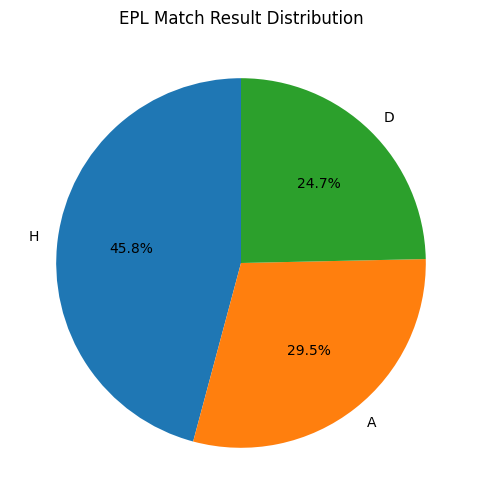

In [ ]:
#pie chart

plt.figure(figsize=(6,6))

plt.pie(
    result_count,
    labels=result_count.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("EPL Match Result Distribution")
plt.show()

In [ ]:
#home win

home_wins = df[df["FullTimeResult"] == "H"]
home_win_count = home_wins["HomeTeam"].value_counts()
print(home_win_count.head(15))

#away win
away_wins = df[df["FullTimeResult"] == "A"]
away_win_count = away_wins["AwayTeam"].value_counts()
print(away_win_count.head(15))

HomeTeam
Man United        318
Arsenal           314
Liverpool         307
Chelsea           299
Man City          293
Tottenham         275
Everton           223
Newcastle         204
West Ham          170
Aston Villa       165
Fulham            142
Southampton       113
Leicester          98
Blackburn          85
Crystal Palace     82
Name: count, dtype: int64
AwayTeam
Man United        234
Chelsea           234
Liverpool         223
Arsenal           220
Man City          207
Tottenham         165
Everton           125
Aston Villa       114
Newcastle         111
West Ham          102
Southampton        73
Crystal Palace     67
Leicester          66
Fulham             57
Blackburn          53
Name: count, dtype: int64


In [ ]:
#total win
total_wins = home_win_count.add(
    away_win_count,
    fill_value=0)
total_wins = total_wins.sort_values(
    ascending=False)

print(total_wins.head(20))

Man United        552
Arsenal           534
Chelsea           533
Liverpool         530
Man City          500
Tottenham         440
Everton           348
Newcastle         315
Aston Villa       279
West Ham          272
Fulham            199
Southampton       186
Leicester         164
Crystal Palace    149
Blackburn         138
Bolton            129
Sunderland        127
Wolves            126
West Brom         116
Stoke             116
Name: count, dtype: int64


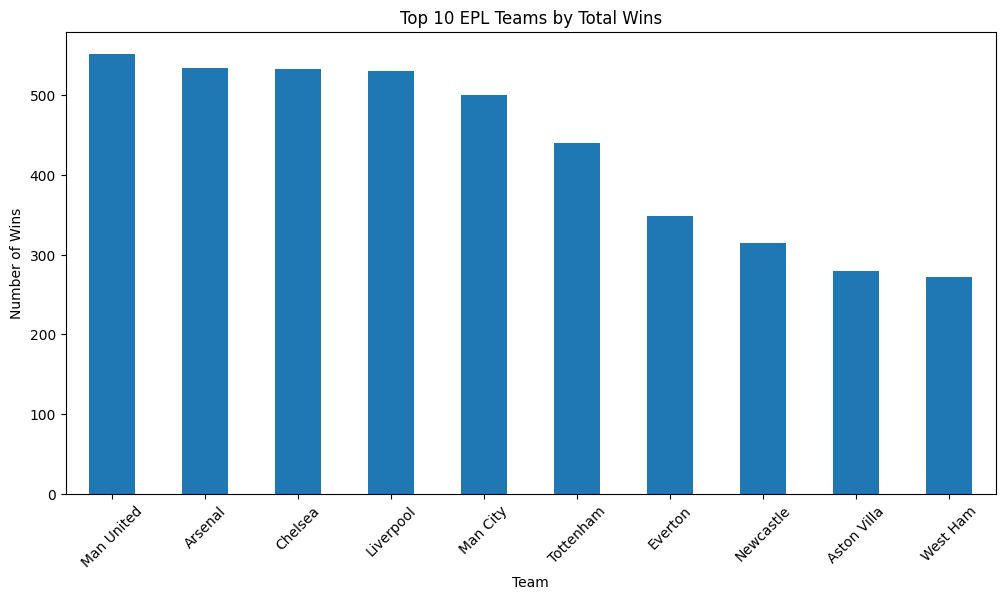

In [ ]:
#top 10 teams by win

plt.figure(figsize=(12, 6))
total_wins.head(10).plot(kind = "bar")

plt.title("Top 10 EPL Teams by Total Wins")
plt.xlabel("Team")
plt.ylabel("Number of Wins")

plt.xticks(rotation=45)
plt.show()

HomeTeam
Arsenal        1778
Liverpool      1747
Man City       1719
Man United     1704
Chelsea        1701
Tottenham      1521
Everton        1202
Newcastle      1152
West Ham       1050
Aston Villa    1038
dtype: int64


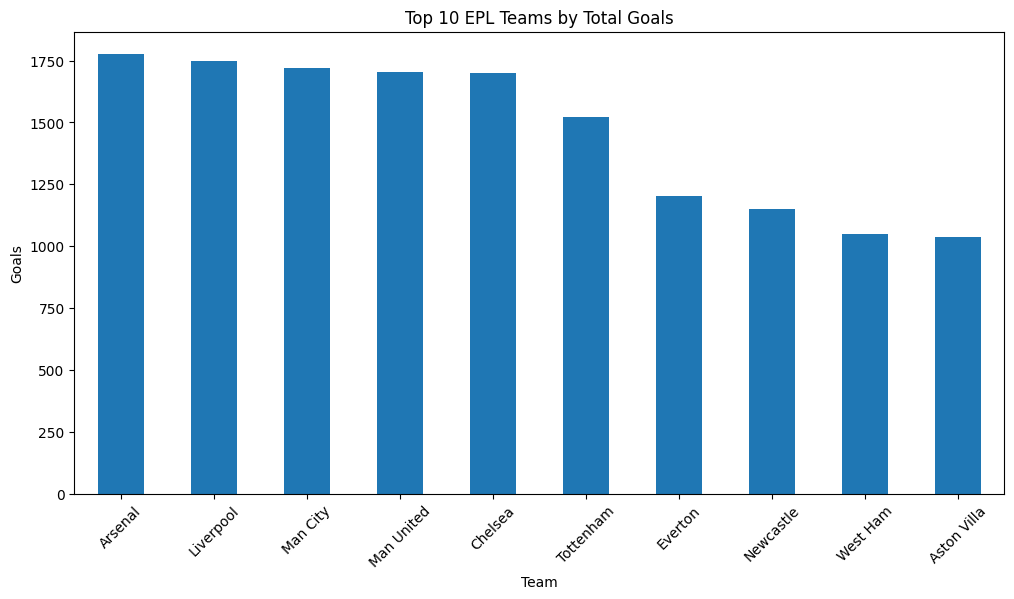

In [ ]:
#Home goals
home_goals = df.groupby("HomeTeam")[
    "FullTimeHomeGoals"
].sum()

#Away goals
away_goals = df.groupby("AwayTeam")[
    "FullTimeAwayGoals"
].sum()

#Total Goals
total_team_goals = home_goals.add(
    away_goals,
    fill_value=0)
total_team_goals = total_team_goals.sort_values(
    ascending=False)

print(total_team_goals.head(10))

#bar graph
plt.figure(figsize=(12, 6))
total_team_goals.head(10).plot(kind="bar")

plt.title("Top 10 EPL Teams by Total Goals")
plt.xlabel("Team")
plt.ylabel("Goals")

plt.xticks(rotation=45)

plt.show()

In [ ]:
#calculate points

df["HomePoints"] = np.select([df["FullTimeResult"] == "H",df["FullTimeResult"] == "D"],[3,1],
default=0)
df["AwayPoints"] = np.select([df["FullTimeResult"] == "A",df["FullTimeResult"] == "D"],[3,1],
default=0)
print(df[["HomeTeam","AwayTeam","FullTimeResult","HomePoints","AwayPoints"]].head(10))

     HomeTeam       AwayTeam FullTimeResult  HomePoints  AwayPoints
0    Charlton       Man City              H           3           0
1     Chelsea       West Ham              H           3           0
2    Coventry  Middlesbrough              A           0           3
3       Derby    Southampton              D           1           1
4       Leeds        Everton              H           3           0
5   Leicester    Aston Villa              D           1           1
6   Liverpool       Bradford              H           3           0
7  Sunderland        Arsenal              H           3           0
8   Tottenham        Ipswich              H           3           0
9  Man United      Newcastle              H           3           0


In [ ]:
#home away point table

home_points = df.groupby("HomeTeam")["HomePoints"].sum()
away_points = df.groupby("AwayTeam")["AwayPoints"].sum()

team_points = pd.DataFrame({
    "HomePoints": home_points,
    "AwayPoints": away_points
}).fillna(0)

team_points["TotalPoints"] = (
    team_points["HomePoints"] +
    team_points["AwayPoints"]
)

team_points = team_points.sort_values(
    "TotalPoints",
    ascending=False
)

print(team_points.head(10))

             HomePoints  AwayPoints  TotalPoints
Man United         1036         817         1853
Arsenal            1039         779         1818
Chelsea            1007         807         1814
Liverpool          1031         782         1813
Man City            951         719         1670
Tottenham           914         612         1526
Everton             788         517         1305
Newcastle           717         440         1157
Aston Villa         614         454         1068
West Ham            615         409         1024


In [ ]:
#home vs away goals

home_avg = df["FullTimeHomeGoals"].mean()

away_avg = df["FullTimeAwayGoals"].mean()

print("Average Home Goals:", home_avg)
print("Average Away Goals:", away_avg)

goal_comparison = pd.DataFrame({
    "Venue": ["Home", "Away"],
    "Average Goals": [
        home_avg,
        away_avg
    ]
})

print(goal_comparison)

Average Home Goals: 1.5353944562899786
Average Away Goals: 1.1826226012793177
  Venue  Average Goals
0  Home       1.535394
1  Away       1.182623


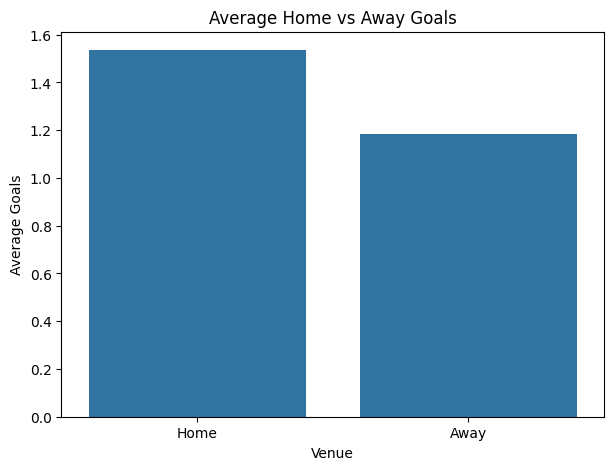

In [ ]:
#bar visualization
plt.figure(figsize=(7, 5))
sns.barplot(
    data=goal_comparison,
    x="Venue",
    y="Average Goals"
)

plt.title("Average Home vs Away Goals")
plt.show()

In [ ]:
#Match analytics

df["TotalShots"] = (df["HomeShots"] + df["AwayShots"])

df["TotalShotsOnTarget"] = (df["HomeShotsOnTarget"] + df["AwayShotsOnTarget"])

df["TotalCorners"] = (df["HomeCorners"] + df["AwayCorners"])

df["TotalFouls"] = (df["HomeFouls"] + df["AwayFouls"])

df["TotalYellowCards"] = (df["HomeYellowCards"] + df["AwayYellowCards"])

df["TotalRedCards"] = (df["HomeRedCards"] + df["AwayRedCards"])

print(df[[
    "HomeTeam",
    "AwayTeam",
    "TotalShots",
    "TotalShotsOnTarget",
    "TotalCorners",
    "TotalFouls",
    "TotalYellowCards",
    "TotalRedCards"
]].head())


   HomeTeam       AwayTeam  TotalShots  TotalShotsOnTarget  TotalCorners  \
0  Charlton       Man City          25                  18            12   
1   Chelsea       West Ham          29                  15            14   
2  Coventry  Middlesbrough          22                  12            12   
3     Derby    Southampton          19                  10            13   
4     Leeds        Everton          29                  14            10   

   TotalFouls  TotalYellowCards  TotalRedCards  
0          25                 3              0  
1          33                 3              0  
2          36                 8              1  
3          24                 2              0  
4          41                 4              0  


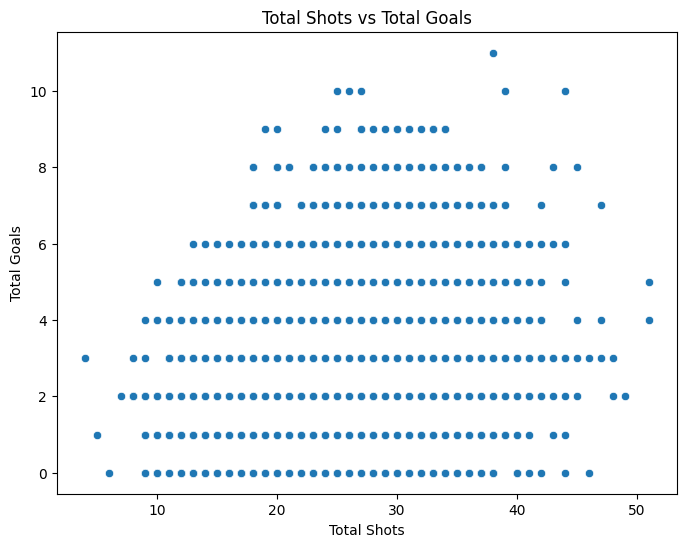

In [ ]:
#shots vs goals

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="TotalShots",
    y="TotalGoals"
)

plt.title("Total Shots vs Total Goals")
plt.xlabel("Total Shots")
plt.ylabel("Total Goals")

plt.show()

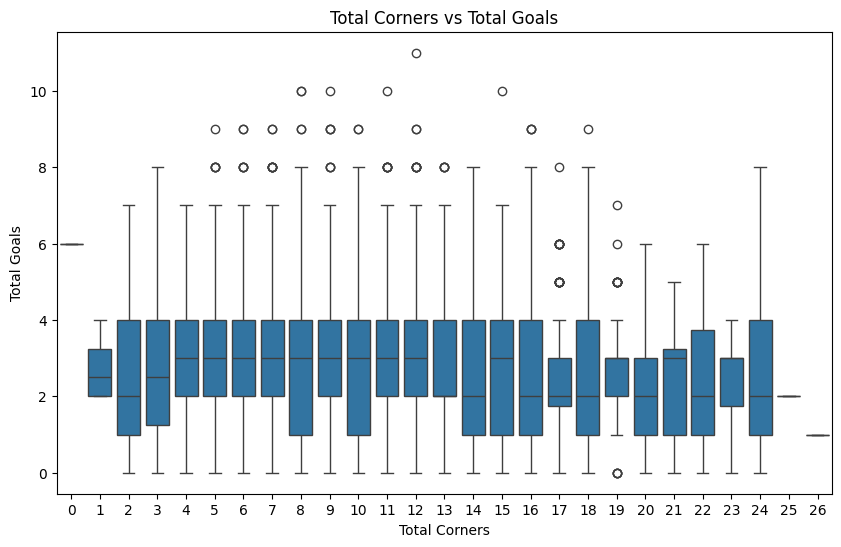

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="TotalCorners",
    y="TotalGoals"
)

plt.title("Total Corners vs Total Goals")
plt.xlabel("Total Corners")
plt.ylabel("Total Goals")

plt.show()

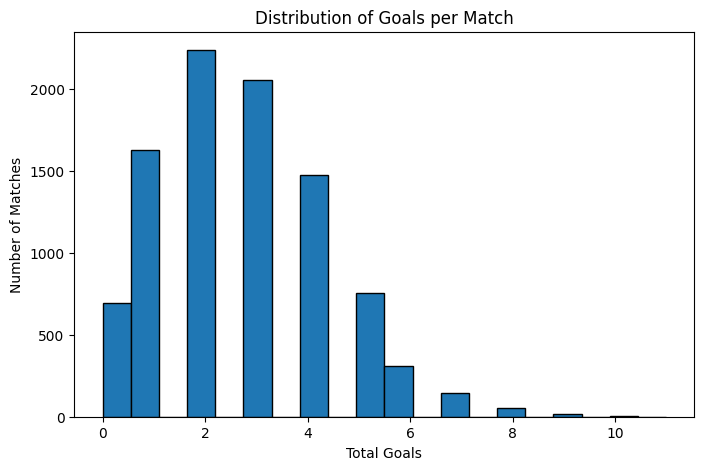

In [ ]:
#Histogram
plt.figure(figsize=(8, 5))
plt.hist(
    df["TotalGoals"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Goals per Match")
plt.xlabel("Total Goals")
plt.ylabel("Number of Matches")

plt.show()

In [ ]:
df["Scoreline"] = (df["FullTimeHomeGoals"].astype(str)+ "-" + df["FullTimeAwayGoals"].astype(str))

print(df["Scoreline"].value_counts().head(10))

Scoreline
1-1    1031
1-0     947
2-1     816
2-0     768
0-0     692
0-1     679
1-2     610
2-2     490
0-2     439
3-1     437
Name: count, dtype: int64


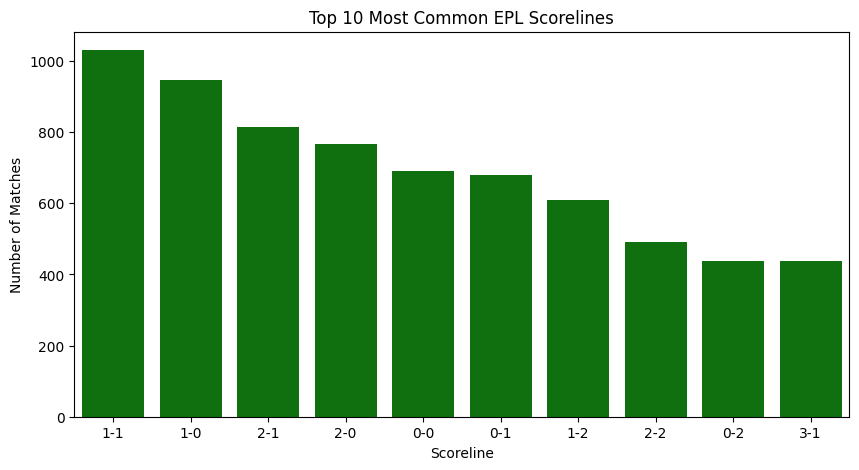

In [ ]:
#common score cards

scorelines = (df["Scoreline"].value_counts().head(10))
plt.figure(figsize=(10, 5))

sns.barplot(x=scorelines.index,
            y=scorelines.values,
            color = "green")

plt.title("Top 10 Most Common EPL Scorelines")
plt.xlabel("Scoreline")
plt.ylabel("Number of Matches")

plt.show()

FullTimeResult     A     D     H
HalfTimeResult                  
A               1578   439   233
D               1007  1405  1428
H                183   469  2638


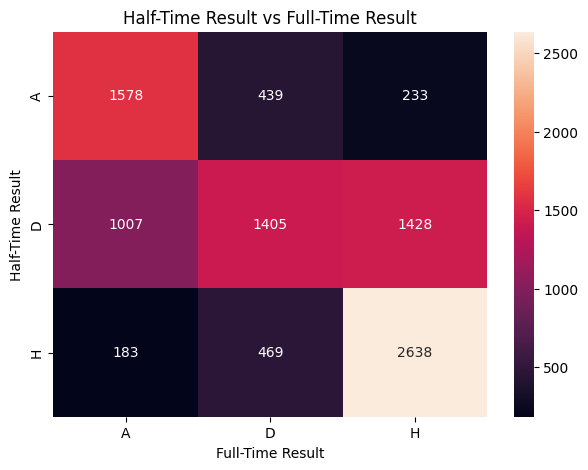

In [ ]:
#Half-Time vs Full-Time Result
result_comparison = pd.crosstab(
    df["HalfTimeResult"],
    df["FullTimeResult"]
)
print(result_comparison)

#Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    result_comparison,
    annot=True,
    fmt="d")

plt.title("Half-Time Result vs Full-Time Result")
plt.xlabel("Full-Time Result")
plt.ylabel("Half-Time Result")

plt.show()

In [ ]:
#correlation - relationship btw 2 variables
numeric_columns = ["FullTimeHomeGoals","FullTimeAwayGoals","TotalGoals","HomeShots","AwayShots","TotalShots",
                   "HomeShotsOnTarget","AwayShotsOnTarget","TotalShotsOnTarget","HomeCorners","AwayCorners",
                   "TotalCorners","HomeFouls","AwayFouls","TotalFouls","TotalYellowCards","TotalRedCards"]
corelation = df[numeric_columns].corr()
print(corelation)

                    FullTimeHomeGoals  FullTimeAwayGoals  TotalGoals  \
FullTimeHomeGoals            1.000000          -0.085113    0.723011   
FullTimeAwayGoals           -0.085113           1.000000    0.626793   
TotalGoals                   0.723011           0.626793    1.000000   
HomeShots                    0.293860          -0.128775    0.140519   
AwayShots                   -0.141545           0.325767    0.115180   
TotalShots                   0.156374           0.144493    0.222473   
HomeShotsOnTarget            0.437995          -0.127921    0.253828   
AwayShotsOnTarget           -0.112793           0.456898    0.228584   
TotalShotsOnTarget           0.268565           0.200844    0.349279   
HomeCorners                  0.040268          -0.077355   -0.022144   
AwayCorners                 -0.080432           0.045762   -0.031171   
TotalCorners                -0.026721          -0.031988   -0.043076   
HomeFouls                   -0.076328          -0.001581   -0.06

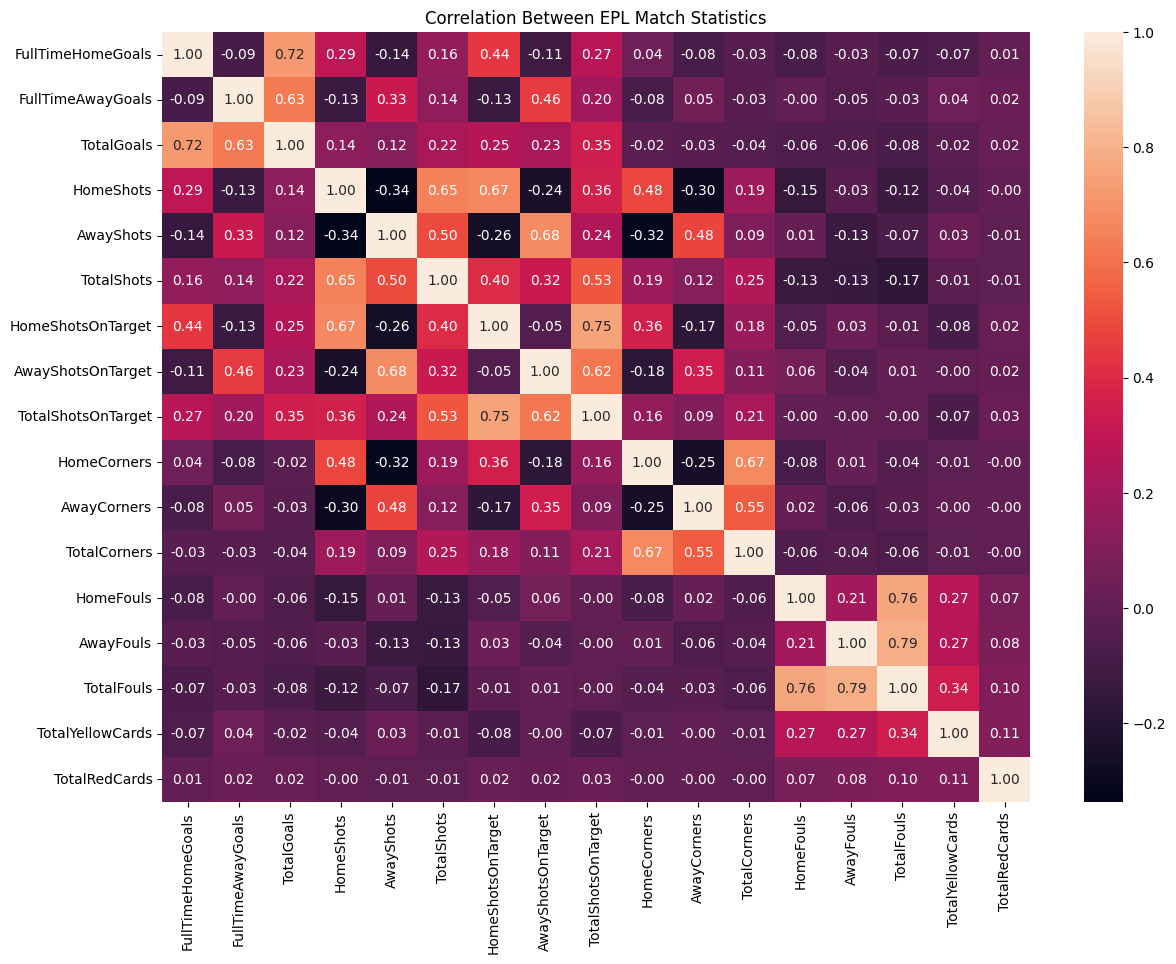

In [ ]:
#corelation heatmap

plt.figure(figsize=(14, 10))

sns.heatmap(
    corelation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between EPL Match Statistics")

plt.show()

#Season wise analysis

In [ ]:
#Matches per season

print(df["Season"].unique())
season_matches = df["Season"].value_counts()
print(season_matches)

['2000/01' '2001/02' '2002/03' '2003/04' '2004/05' '2005/06' '2006/07'
 '2007/08' '2008/09' '2009/10' '2010/11' '2011/12' '2012/13' '2013/14'
 '2014/15' '2015/16' '2016/17' '2017/18' '2018/19' '2019/20' '2020/21'
 '2021/22' '2022/23' '2023/24' '2024/25']
Season
2000/01    380
2001/02    380
2002/03    380
2006/07    380
2005/06    380
2007/08    380
2008/09    380
2010/11    380
2009/10    380
2017/18    380
2018/19    380
2011/12    380
2012/13    380
2013/14    380
2014/15    380
2015/16    380
2016/17    380
2021/22    380
2022/23    380
2019/20    380
2020/21    380
2023/24    380
2024/25    350
2003/04    335
2004/05    335
Name: count, dtype: int64


Season
2000/01     992
2001/02    1001
2002/03    1000
2003/04     883
2004/05     851
2005/06     944
2006/07     931
2007/08    1002
2008/09     942
2009/10    1053
2010/11    1063
2011/12    1066
2012/13    1063
2013/14    1052
2014/15     975
2015/16    1026
2016/17    1064
2017/18    1018
2018/19    1072
2019/20    1034
2020/21    1024
2021/22    1071
2022/23    1084
2023/24    1246
2024/25    1038
Name: TotalGoals, dtype: int64


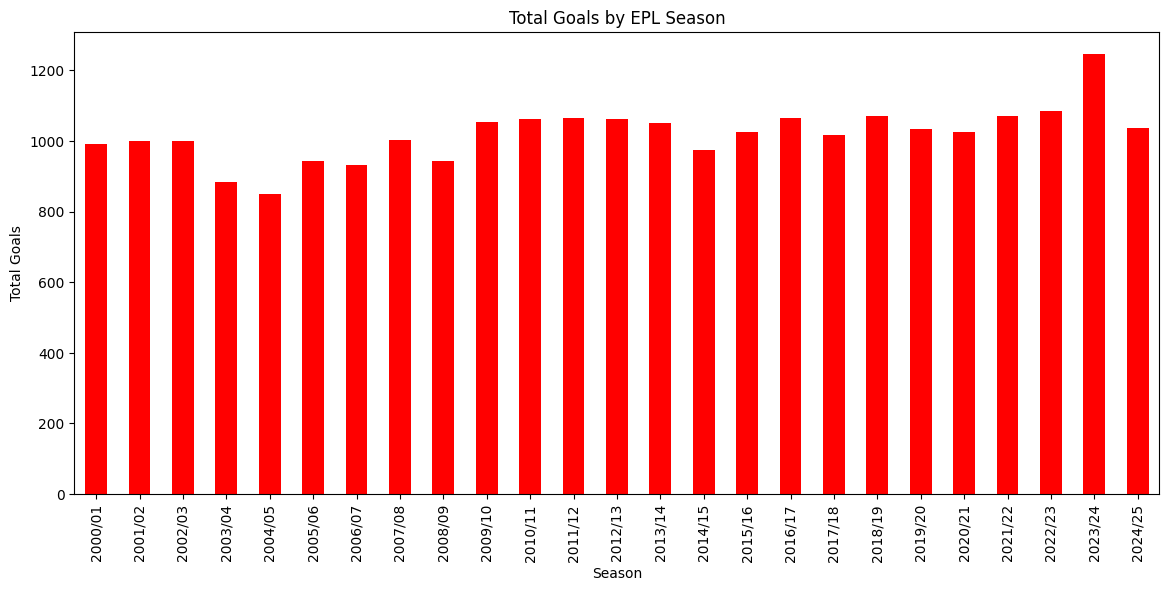

In [ ]:
#total goals by season

season_goals = df.groupby("Season")["TotalGoals"].sum()
print(season_goals)

#bar graph
plt.figure(figsize=(14, 6))
season_goals.plot(kind="bar",color = "red")

plt.title("Total Goals by EPL Season")
plt.xlabel("Season")
plt.ylabel("Total Goals")

plt.xticks(rotation=90)

plt.show()

In [ ]:
#High scoring matches
top_matches = df.sort_values("TotalGoals",ascending=False)
print(top_matches[["Season","MatchDate","HomeTeam","AwayTeam","FullTimeHomeGoals",
                   "FullTimeAwayGoals","TotalGoals"]].head(10))

       Season  MatchDate     HomeTeam     AwayTeam  FullTimeHomeGoals  \
2641  2007/08 2007-09-29   Portsmouth      Reading                  7   
2764  2007/08 2007-12-29    Tottenham      Reading                  6   
3456  2009/10 2009-11-22    Tottenham        Wigan                  9   
4658  2012/13 2012-12-29      Arsenal    Newcastle                  7   
4115  2011/12 2011-08-28   Man United      Arsenal                  8   
4847  2012/13 2013-05-19    West Brom   Man United                  5   
7717  2020/21 2021-02-02   Man United  Southampton                  9   
7220  2019/20 2019-10-25  Southampton    Leicester                  0   
7547  2020/21 2020-10-04  Aston Villa    Liverpool                  7   
3530  2009/10 2010-01-16      Chelsea   Sunderland                  7   

      FullTimeAwayGoals  TotalGoals  
2641                  4          11  
2764                  4          10  
3456                  1          10  
4658                  3          10  
4115  

In [ ]:
# Interpretation

# #TeamPerformance:
# The dataset shows clear differences in team performance. Teams such as Manchester United, Arsenal, Chelsea, Liverpool, and Manchester City have recorded a large number of wins and points across the seasons covered.

# #HomeAdvantage:
# Home teams won approximately 45.8% of the matches, compared with around 29.5% away wins. This indicates a noticeable home advantage in the EPL. Draws accounted for approximately 24.7% of matches.

# #Goals:
# The average number of goals per match is around 2.72, with a median of 3 goals. On average, home teams scored about 1.54 goals, while away teams scored around 1.18 goals, showing that home teams generally score more.

# #ShotsVsGoals:
# There is a weak positive relationship between total shots and total goals, with a correlation of approximately 0.22. This means taking more shots is associated with more goals to some extent, but shots alone do not strongly determine the final score.

# #ShotsOnTargetVsGoals:
# Shots on target have a stronger positive relationship with goals, with a correlation of approximately 0.35. This suggests that creating accurate attempts is more closely associated with scoring than simply taking a large number of shots.

# #Discipline:
# The dataset also contains information about fouls, yellow cards, and red cards. These variables can be used to study disciplinary patterns and how match discipline may be associated with match results.

# #OverallInterpretation:
# The analysis shows that EPL match outcomes are influenced by several factors, including home advantage, attacking performance, shots on target, and team consistency. No single variable completely determines whether a team wins or loses.

In [ ]:
# Decision Making

# #ImproveAttackingEfficiency:
# Teams should focus not only on increasing the number of shots but also on creating more shots on target, since shots on target show a stronger relationship with goals.

# #UseHomeAdvantage:
# Since home teams win a larger proportion of matches, teams can place greater emphasis on performing consistently in home matches and making effective use of home conditions.

# #FocusOnGoalScoring:
# With an average of approximately 2.72 goals per match, attacking and finishing ability are important areas for team performance. Training can focus on improving finishing and converting opportunities.

# #ShotQuality:
# The stronger relationship between shots on target and goals suggests that shot accuracy and quality should receive more attention than simply increasing the total number of attempts.

# #TeamStrategy:
# Historical performance data such as wins, goals scored, and points can be used to identify areas where teams need improvement. Teams can compare their attacking and defensive records to develop suitable strategies.

# #DisciplineManagement:
# Coaches should monitor fouls, yellow cards, and red cards and work on reducing unnecessary disciplinary incidents, as maintaining a disciplined squad can help avoid situations that negatively affect matches.

# #OverallDecision:
# EPL teams should make decisions using a combination of match results, home performance, goals, shots, shots on target, and discipline. The analysis suggests that improving the quality of attacking opportunities and maintaining consistent performance, particularly at home, can be important areas for team strategy.